In [15]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [16]:
df_DE = df[df['job_country'] == 'Germany']

In [17]:
df_DE['job_location'].value_counts().head(10)

job_location
Berlin, Germany        4480
Munich, Germany        2641
Germany                2447
Hamburg, Germany       1728
Anywhere               1328
Frankfurt, Germany     1315
Cologne, Germany        888
Düsseldorf, Germany     880
Stuttgart, Germany      803
Essen, Germany          387
Name: count, dtype: int64

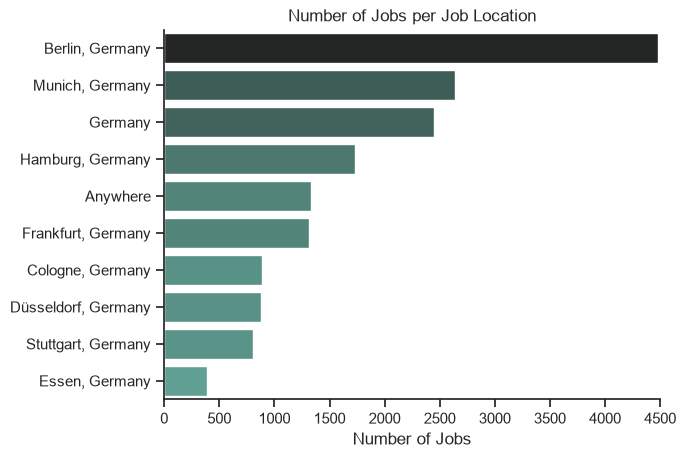

In [23]:
df_for_plot = df_DE['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_for_plot, x='count', y='job_location', hue='count', palette='dark:#5A9_r', legend=False)
sns.despine()
plt.title('Number of Jobs per Job Location')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.xlim(0, 4500)
plt.show()


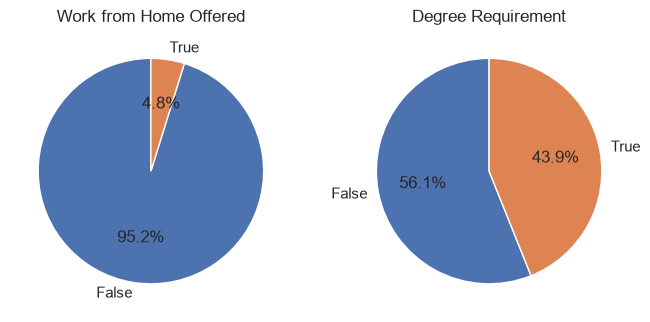

In [19]:
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement'
}

fig, ax = plt.subplots(1, 2)
fig.set_size_inches((8, 5))

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_DE[column].value_counts(), labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
    ax[i].set_title(title)

plt.show()

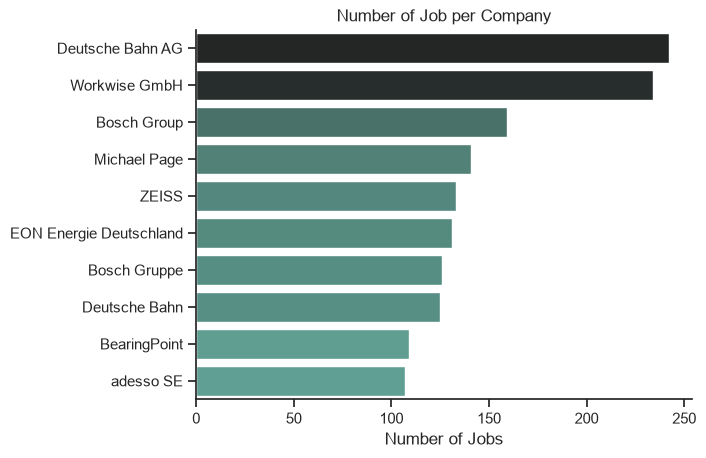

In [20]:
df_for_plot = df_DE['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_for_plot, x='count', y='company_name', hue='count', palette='dark:#5A9_r', legend=False)
sns.despine()
plt.title('Number of Job per Company')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()
